In [29]:
import tensorflow as tf
import numpy as np
import os
import pathlib
import time
import datetime

from matplotlib import pyplot as plt
from IPython import display

In [30]:
dataset_name = "facades" #@param ["cityscapes", "edges2handbags", "edges2shoes", "facades", "maps", "night2day"]
_URL = f'http://efrosgans.eecs.berkeley.edu/pix2pix/datasets/{dataset_name}.tar.gz'

path_to_zip = tf.keras.utils.get_file(
    fname=f"{dataset_name}.tar.gz",
    origin=_URL,
    extract=True)

path_to_zip  = pathlib.Path(path_to_zip)

PATH = path_to_zip.parent/dataset_name

In [31]:
sample_image = tf.io.read_file(str(PATH / 'train/1.jpg'))
sample_image = tf.io.decode_jpeg(sample_image)
print(sample_image.shape)

(256, 512, 3)


In [32]:
def load(image_file):
  # Read and decode an image file to a uint8 tensor
  image = tf.io.read_file(image_file)
  image = tf.io.decode_jpeg(image)

  # Split each image tensor into two tensors:
  # - one with a real building facade image
  # - one with an architecture label image 
  w = tf.shape(image)[1]
  w = w // 2
  input_image = image[:, w:, :]
  real_image = image[:, :w, :]

  # Convert both images to float32 tensors
  input_image = tf.cast(input_image, tf.float32)
  real_image = tf.cast(real_image, tf.float32)

  return input_image, real_image

In [33]:
inp, re = load(str(PATH / 'train/100.jpg'))
inp

<tf.Tensor: shape=(256, 256, 3), dtype=float32, numpy=
array([[[  7.,   6., 172.],
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        ...,
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        [  0.,   0., 222.]],

       [[  7.,   6., 172.],
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        ...,
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        [  0.,   0., 222.]],

       [[  7.,   6., 172.],
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        ...,
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        [  0.,   0., 222.]],

       ...,

       [[  7.,   6., 172.],
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        ...,
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        [  0.,   0., 222.]],

       [[  7.,   6., 172.],
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        ...,
        [  0.,   0., 222.],
        [  0.,   0., 222.],
        [  0.,   0., 222.]],

       [[  7.,   

In [34]:
def downsample(filters, size, apply_batchnorm=True):
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
      tf.keras.layers.Conv2D(filters, size, strides=2, padding='same',
                             kernel_initializer=initializer, use_bias=False))

  if apply_batchnorm:
    result.add(tf.keras.layers.BatchNormalization())

  result.add(tf.keras.layers.LeakyReLU())

  return result

In [35]:
def upsample(filters, size, apply_dropout=False):
  initializer = tf.random_normal_initializer(0., 0.02)

  result = tf.keras.Sequential()
  result.add(
    tf.keras.layers.Conv2DTranspose(filters, size, strides=2,
                                    padding='same',
                                    kernel_initializer=initializer,
                                    use_bias=False))

  result.add(tf.keras.layers.BatchNormalization())

  if apply_dropout:
      result.add(tf.keras.layers.Dropout(0.5))

  result.add(tf.keras.layers.ReLU())

  return result

In [36]:
def Generator():
  inputs = tf.keras.layers.Input(shape=[256, 256, 3])

  down_stack = [
    downsample(64, 4, apply_batchnorm=False),  # (batch_size, 128, 128, 64)
    downsample(128, 4),  # (batch_size, 64, 64, 128)
    downsample(256, 4),  # (batch_size, 32, 32, 256)
    downsample(512, 4),  # (batch_size, 16, 16, 512)
    downsample(512, 4),  # (batch_size, 8, 8, 512)
    downsample(512, 4),  # (batch_size, 4, 4, 512)
    downsample(512, 4),  # (batch_size, 2, 2, 512)
    downsample(512, 4),  # (batch_size, 1, 1, 512)
  ]

  up_stack = [
    upsample(512, 4, apply_dropout=True),  # (batch_size, 2, 2, 1024)
    upsample(512, 4, apply_dropout=True),  # (batch_size, 4, 4, 1024)
    upsample(512, 4, apply_dropout=True),  # (batch_size, 8, 8, 1024)
    upsample(512, 4),  # (batch_size, 16, 16, 1024)
    upsample(256, 4),  # (batch_size, 32, 32, 512)
    upsample(128, 4),  # (batch_size, 64, 64, 256)
    upsample(64, 4),  # (batch_size, 128, 128, 128)
  ]

  initializer = tf.random_normal_initializer(0., 0.02)
  last = tf.keras.layers.Conv2DTranspose(OUTPUT_CHANNELS, 4,
                                         strides=2,
                                         padding='same',
                                         kernel_initializer=initializer,
                                         activation='tanh')  # (batch_size, 256, 256, 3)

  x = inputs

  # Downsampling through the model
  skips = []
  for down in down_stack:
    x = down(x)
    skips.append(x)

  skips = reversed(skips[:-1])

  # Upsampling and establishing the skip connections
  for up, skip in zip(up_stack, skips):
    x = up(x)
    x = tf.keras.layers.Concatenate()([x, skip])

  x = last(x)

  return tf.keras.Model(inputs=inputs, outputs=x)

In [37]:


OUTPUT_CHANNELS = 3

generator = Generator()
tf.keras.utils.plot_model(generator, show_shapes=True, dpi=64)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model/model_to_dot to work.


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


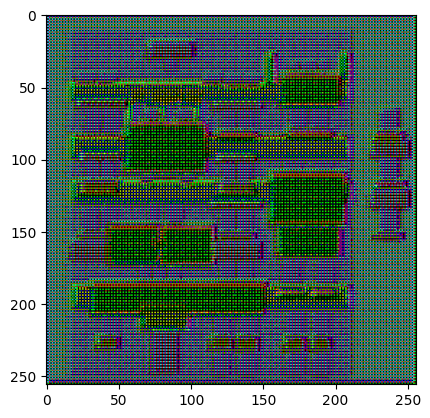

In [38]:
gen_output = generator(inp[tf.newaxis, ...], training=False)
plt.imshow(gen_output[0, ...])

In [39]:
LAMBDA = 100

In [40]:
loss_object = tf.keras.losses.BinaryCrossentropy(from_logits=True)

In [41]:
def generator_loss(disc_generated_output, gen_output, target):
  gan_loss = loss_object(tf.ones_like(disc_generated_output), disc_generated_output)

  # Mean absolute error
  l1_loss = tf.reduce_mean(tf.abs(target - gen_output))

  total_gen_loss = gan_loss + (LAMBDA * l1_loss)

  return total_gen_loss, gan_loss, l1_loss

In [42]:
def Discriminator():
  initializer = tf.random_normal_initializer(0., 0.02)

  inp = tf.keras.layers.Input(shape=[256, 256, 3], name='input_image')
  tar = tf.keras.layers.Input(shape=[256, 256, 3], name='target_image')

  x = tf.keras.layers.concatenate([inp, tar])  # (batch_size, 256, 256, channels*2)

  down1 = downsample(64, 4, False)(x)  # (batch_size, 128, 128, 64)
  down2 = downsample(128, 4)(down1)  # (batch_size, 64, 64, 128)
  down3 = downsample(256, 4)(down2)  # (batch_size, 32, 32, 256)

  zero_pad1 = tf.keras.layers.ZeroPadding2D()(down3)  # (batch_size, 34, 34, 256)
  conv = tf.keras.layers.Conv2D(512, 4, strides=1,
                                kernel_initializer=initializer,
                                use_bias=False)(zero_pad1)  # (batch_size, 31, 31, 512)

  batchnorm1 = tf.keras.layers.BatchNormalization()(conv)

  leaky_relu = tf.keras.layers.LeakyReLU()(batchnorm1)

  zero_pad2 = tf.keras.layers.ZeroPadding2D()(leaky_relu)  # (batch_size, 33, 33, 512)

  last = tf.keras.layers.Conv2D(1, 4, strides=1,
                                kernel_initializer=initializer)(zero_pad2)  # (batch_size, 30, 30, 1)

  return tf.keras.Model(inputs=[inp, tar], outputs=last)

In [43]:
discriminator = Discriminator()


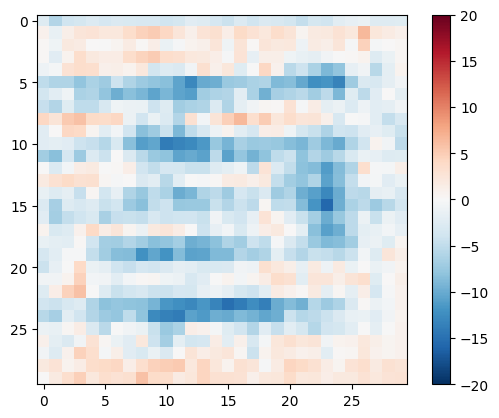

In [44]:
disc_out = discriminator([inp[tf.newaxis, ...], gen_output], training=False)
plt.imshow(disc_out[0, ..., -1], vmin=-20, vmax=20, cmap='RdBu_r')
plt.colorbar()

In [45]:
def discriminator_loss(disc_real_output, disc_generated_output):
  real_loss = loss_object(tf.ones_like(disc_real_output), disc_real_output)

  generated_loss = loss_object(tf.zeros_like(disc_generated_output), disc_generated_output)

  total_disc_loss = real_loss + generated_loss

  return total_disc_loss

In [46]:
generator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

In [48]:
checkpoint_dir = './training_checkpoints'
checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
checkpoint = tf.train.Checkpoint(generator_optimizer=generator_optimizer,
                                 discriminator_optimizer=discriminator_optimizer,
                                 generator=generator,
                                 discriminator=discriminator)

In [49]:
def generate_images(model, test_input, tar):
  prediction = model(test_input, training=True)
  plt.figure(figsize=(15, 15))

  display_list = [test_input[0], tar[0], prediction[0]]
  title = ['Input Image', 'Ground Truth', 'Predicted Image']

  for i in range(3):
    plt.subplot(1, 3, i+1)
    plt.title(title[i])
    # Getting the pixel values in the [0, 1] range to plot.
    plt.imshow(display_list[i] * 0.5 + 0.5)
    plt.axis('off')
  plt.show()

In [72]:
checkpoint.restore(tf.train.latest_checkpoint("../../../sandbox/modules/pytorch/himalaya_ckpt"))

In [61]:
def load_image_train(image_file):
  input_image, real_image = load(image_file)
  input_image, real_image = random_jitter(input_image, real_image)
  input_image, real_image = normalize(input_image, real_image)

  return input_image, real_image

In [62]:
def load_image_test(image_file):
  input_image, real_image = load(image_file)
  input_image, real_image = resize(input_image, real_image,
                                   IMG_HEIGHT, IMG_WIDTH)
  input_image, real_image = normalize(input_image, real_image)

  return input_image, real_image

In [63]:
@tf.function()
def random_jitter(input_image, real_image):
  # Resizing to 286x286
  input_image, real_image = resize(input_image, real_image, 286, 286)

  # Random cropping back to 256x256
  input_image, real_image = random_crop(input_image, real_image)

  if tf.random.uniform(()) > 0.5:
    # Random mirroring
    input_image = tf.image.flip_left_right(input_image)
    real_image = tf.image.flip_left_right(real_image)

  return input_image, real_image

In [64]:
# Normalizing the images to [-1, 1]
def normalize(input_image, real_image):
  input_image = (input_image / 127.5) - 1
  real_image = (real_image / 127.5) - 1

  return input_image, real_image

In [65]:
def random_crop(input_image, real_image):
  stacked_image = tf.stack([input_image, real_image], axis=0)
  cropped_image = tf.image.random_crop(
      stacked_image, size=[2, IMG_HEIGHT, IMG_WIDTH, 3])

  return cropped_image[0], cropped_image[1]

In [66]:
def resize(input_image, real_image, height, width):
  input_image = tf.image.resize(input_image, [height, width],
                                method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)
  real_image = tf.image.resize(real_image, [height, width],
                               method=tf.image.ResizeMethod.NEAREST_NEIGHBOR)

  return input_image, real_image

In [67]:
# The facade training set consist of 400 images
BUFFER_SIZE = 400
# The batch size of 1 produced better results for the U-Net in the original pix2pix experiment
BATCH_SIZE = 1
# Each image is 256x256 in size
IMG_WIDTH = 256
IMG_HEIGHT = 256

In [68]:
train_dataset = tf.data.Dataset.list_files(str(PATH / 'train/*.jpg'))
train_dataset = train_dataset.map(load_image_train,
                                  num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)

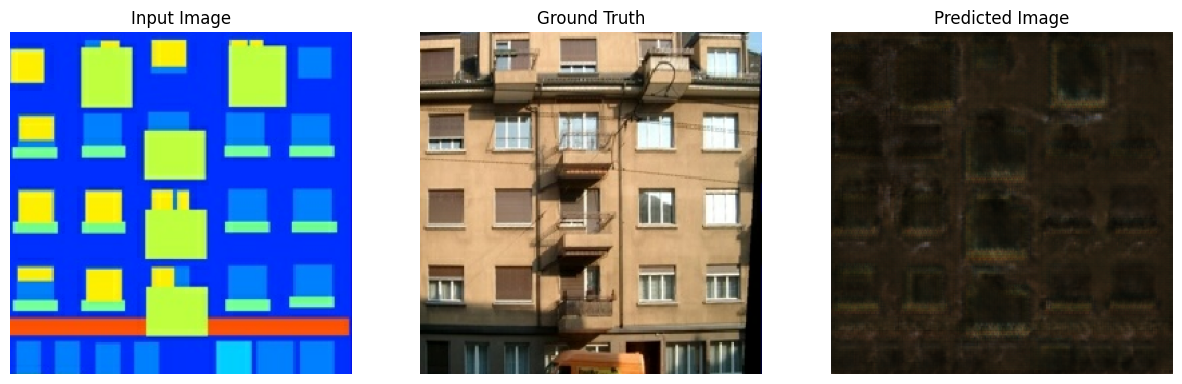

In [69]:
for example_input, example_target in train_dataset.take(1):
  generate_images(generator, example_input, example_target)

In [70]:
checkpoint.restore(tf.train.latest_checkpoint("checkpoints/training_checkpoints/"))

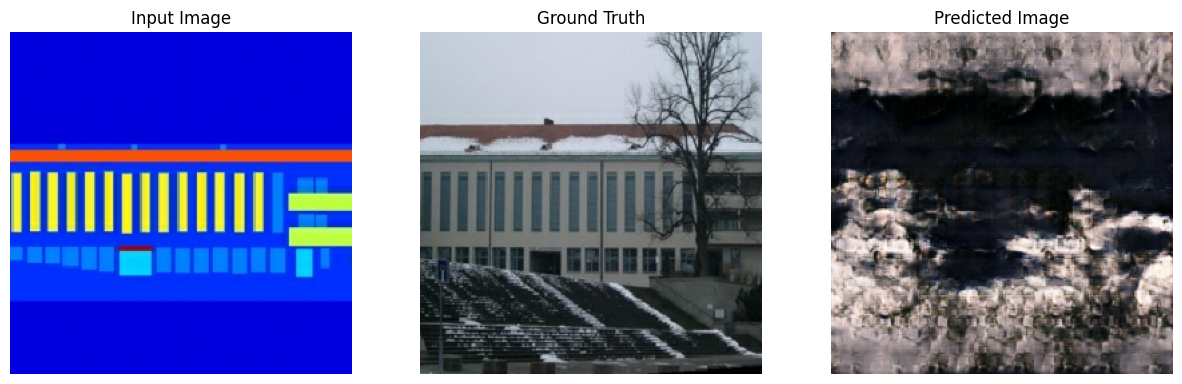

In [71]:
for example_input, example_target in train_dataset.take(1):
  generate_images(generator, example_input, example_target)

In [124]:
import panel as pn
import numpy as np
from matplotlib import use
import time

NameError: name 'img' is not defined

In [ ]:
X = np.linspace(-1,1, 256)
Y = np.linspace(-1,1,256)

XX, YY = np.meshgrid(X,Y)
ZZ = np.sin(XX**2+YY**2).reshape((256,256,1))
tf.constant(np.repeat(ZZ,3,axis=2)).shape

1.0


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


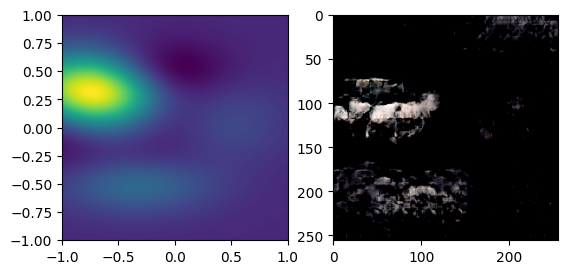

In [95]:


X = np.linspace(-1,2, 256)
Y = np.linspace(-3,3,256)

XX, YY = np.meshgrid(X,Y)

ZZ = 2 * (1-XX)**2 * np.exp(-XX**2-(YY+1)**2)-1*(XX/5-XX**3-YY**5)*np.exp(-XX**2-YY**2)-1/3*np.exp(-(XX+1)**2-YY**2)
dz = np.max(ZZ) - np.min(ZZ)
ZZ= (ZZ.reshape((256,256,1)) - np.min(ZZ)) / dz * 2 - 1 
print(np.max(ZZ))
#ZZ = np.sin(XX**2+YY**2).reshape((256,256,1))*2-1

fig, ax = plt.subplots(1,2)
ax[0].imshow(ZZ, extent=[-1, 1,-1,1])

img = tf.cast(tf.constant(np.repeat(ZZ,3,axis=2)), tf.float32)
prediction = generator(img[tf.newaxis, ...], training=True)


ax[1].imshow(prediction[0])
#draw_surf(1,1)

In [ ]:
img = tf.cast(tf.constant(np.repeat(ZZ,3,axis=2)), tf.float32)
gen_output = generator(img[tf.newaxis, ...], training=False)

In [ ]:

plt.imshow(gen_output[0, ...])
plt.show()

In [123]:
fac=np.linspace(-0.95,-0.05,20)
check = np.array([-1,1])
for ifac in fac:
    print(check*np.abs(ifac)+(1+ifac))

[-0.9  1. ]
[-0.80526316  1.        ]
[-0.71052632  1.        ]
[-0.61578947  1.        ]
[-0.52105263  1.        ]
[-0.42631579  1.        ]
[-0.33157895  1.        ]
[-0.23684211  1.        ]
[-0.14210526  1.        ]
[-0.04736842  1.        ]
[0.04736842 1.        ]
[0.14210526 1.        ]
[0.23684211 1.        ]
[0.33157895 1.        ]
[0.42631579 1.        ]
[0.52105263 1.        ]
[0.61578947 1.        ]
[0.71052632 1.        ]
[0.80526316 1.        ]
[0.9 1. ]


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


2.1346109000005526


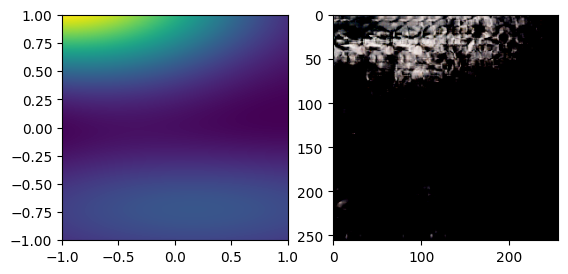

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.2050149999995483


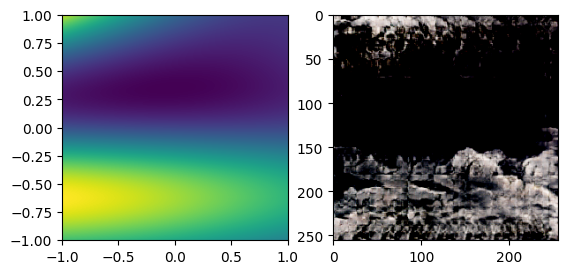

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.21627980000630487


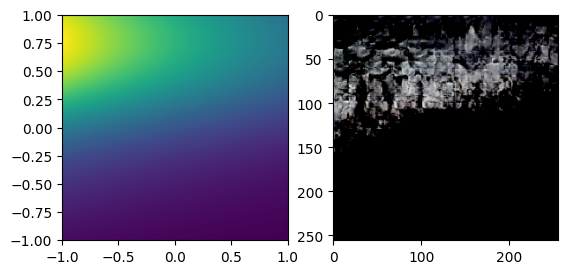

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.20486990000063088


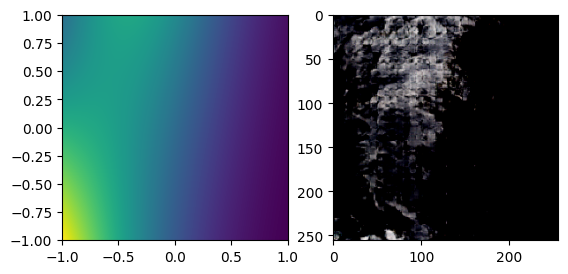

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.21675710000272375


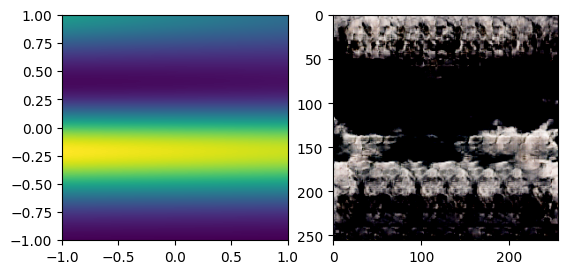

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.21972689998801798


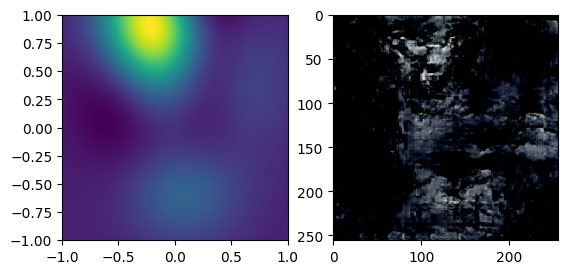

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.1862249999976484


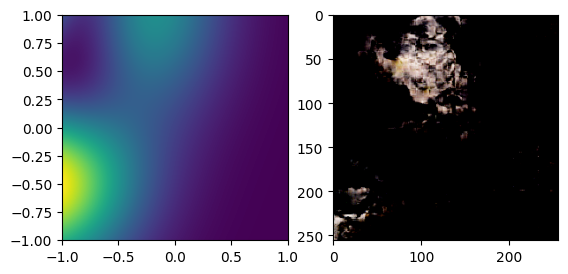

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.19626850000349805


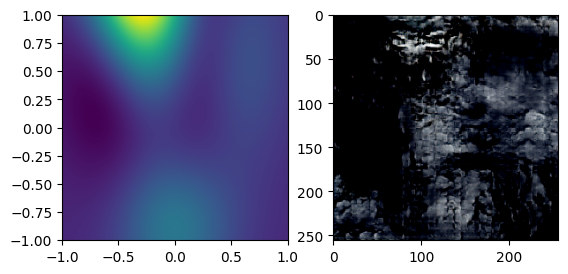

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.20108220000111032


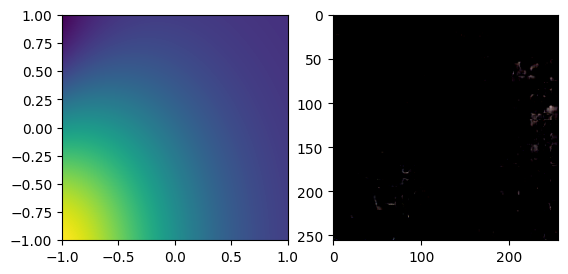

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.20776450000994373


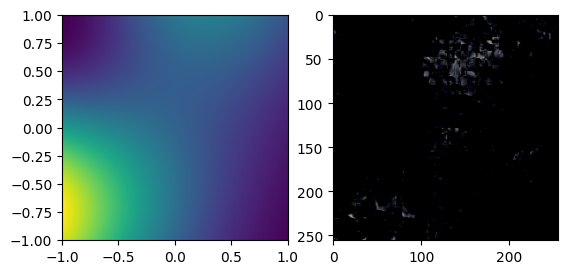

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.18462020000151824


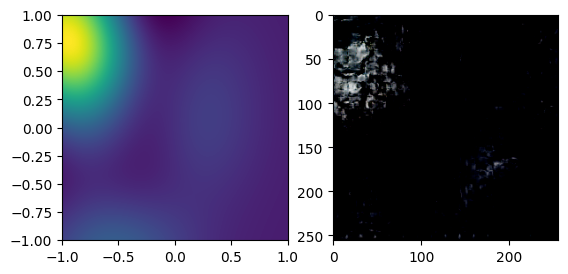

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.18568579999555368


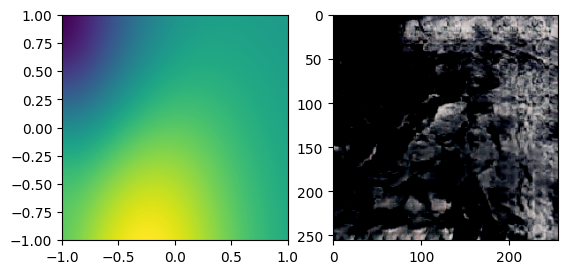

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.18872279999777675


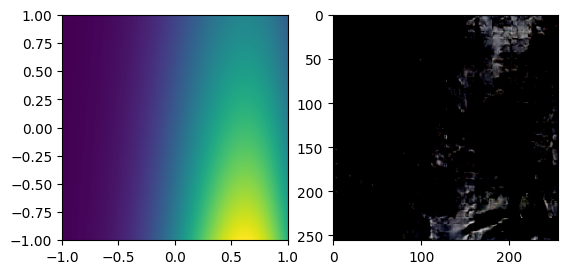

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.1940521000069566


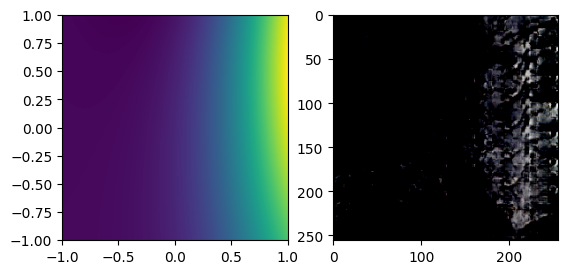

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.1824437999894144


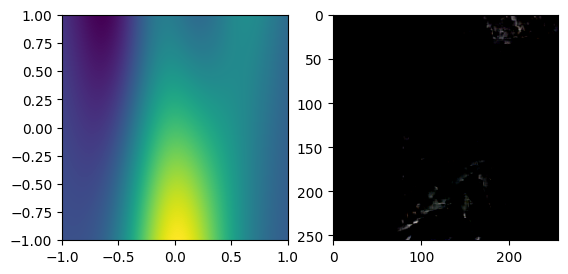

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.18424430000595748


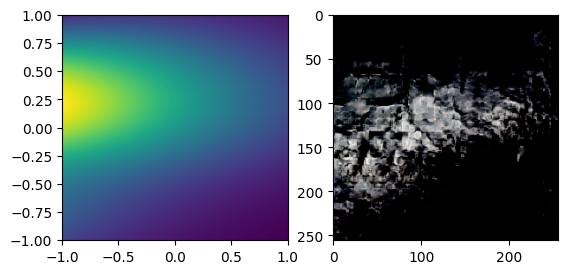

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.19443909999972675


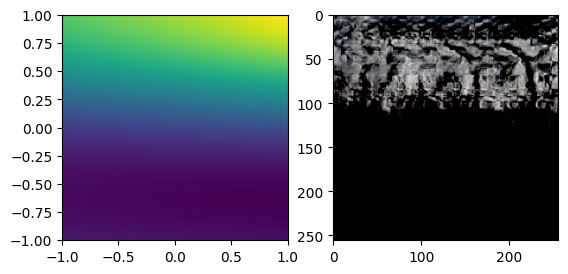

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.21041450000484474


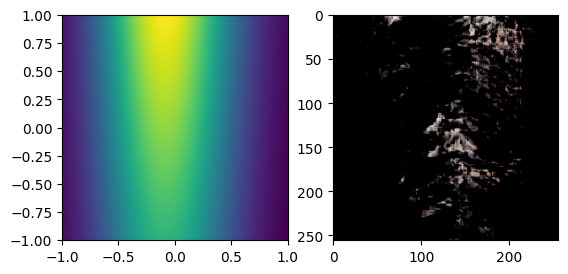

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.15310919999319594


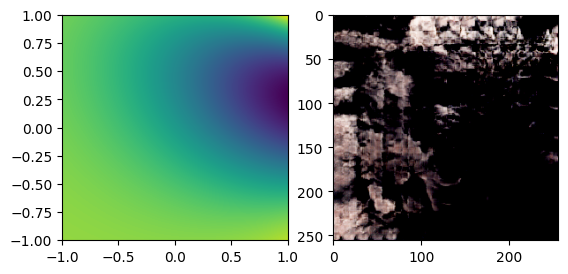

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.18881819999660365


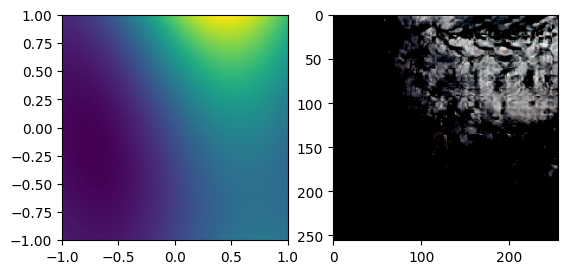

In [144]:
fac=np.linspace(0.95,0.05,20)
check = np.array([-1,1])
for ifac in fac:
    
    t = time.perf_counter()
    #ifac = np.random.choice(fac)
    #print(check*ifac-(1-ifac))
    x_draw = np.sort(np.random.uniform(-3,3,2))
    y_draw = np.sort(np.random.uniform(-3,3,2))
    X = np.linspace(x_draw[0],x_draw[1], 256)
    Y = np.linspace(y_draw[0],y_draw[1], 256)
    #X = np.linspace(-3*ifac, 3*ifac, 256)
    #Y = np.linspace(-3*ifac, 3*ifac, 256) 
    XX, YY = np.meshgrid(X,Y)
    
    ZZ = 2 * (1-XX)**2 * np.exp(-XX**2-(YY+1)**2)-1*(XX/5-XX**3-YY**5)*np.exp(-XX**2-YY**2)-1/3*np.exp(-(XX+1)**2-YY**2)
    dz = np.max(ZZ) - np.min(ZZ)
    ZZ= (ZZ.reshape((256,256,1)) - np.min(ZZ)) / dz * 2 - 1 
    Z = ZZ * ifac - (1-ifac)
    
    #ZZ = np.sin(XX**2+YY**2).reshape((256,256,1))*2-1
    
    fig, ax = plt.subplots(1,2)
    ax[0].imshow(ZZ, extent=[-1, 1,-1,1])
    #ax[0].set_title(str(check*ifac-(1-ifac)))
    img = tf.cast(tf.constant(np.repeat(ZZ,3,axis=2)), tf.float32)
    prediction = generator(img[tf.newaxis, ...], training=True)

    print(time.perf_counter() - t)
    
    ax[1].imshow(prediction[0])
    plt.show()

In [30]:
model = Generator()

# Load the previously saved weights
model.load_weights(r"C:\Users\chudalla\Downloads\pix2pix_himalaya_80k.h5")


OSError: Unable to synchronously open file (file signature not found)

In [2]:
import sys
sys.path.append("../../../sandbox/modules/pytorch")

In [3]:
import build_model
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

In [4]:
model = build_model.pix2pix_model()
model.load_model("../../../sandbox/modules/pytorch/himalaya_smooth_ckpt")

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


4.294459400000001


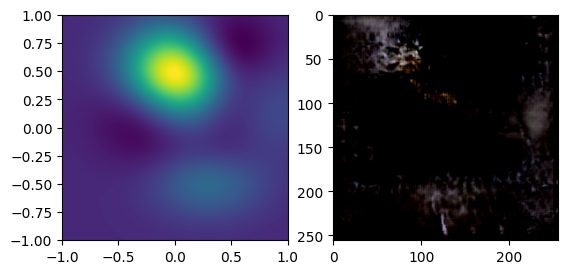

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.054383300000001356


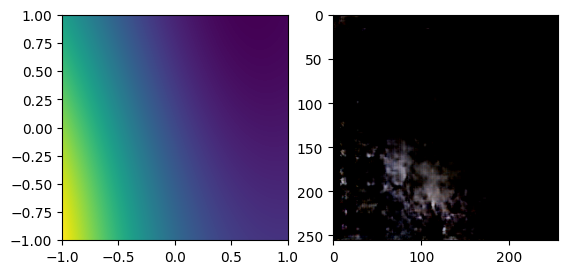

0.04801329999999737


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


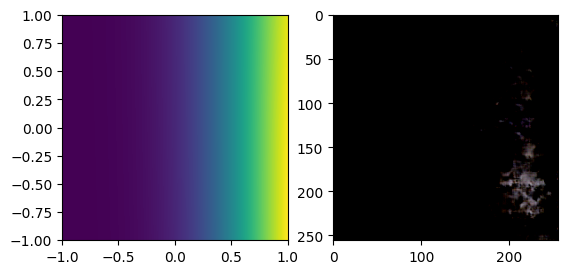

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.04419980000000123


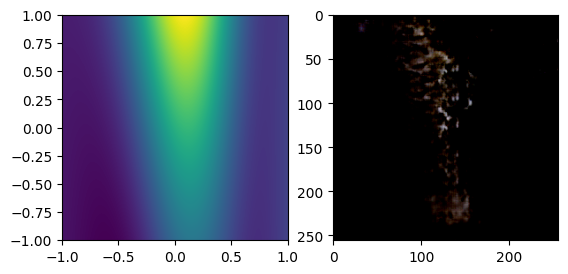

0.04743129999999951


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


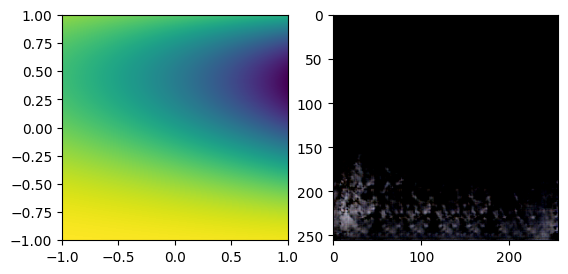

0.04594810000000038

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


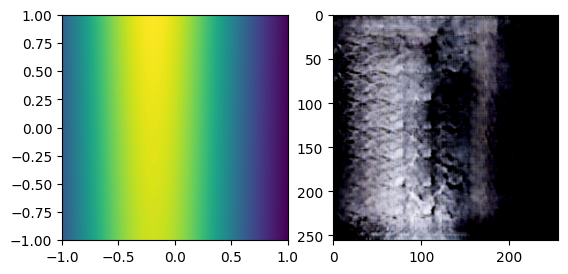

0.0438590000000012


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


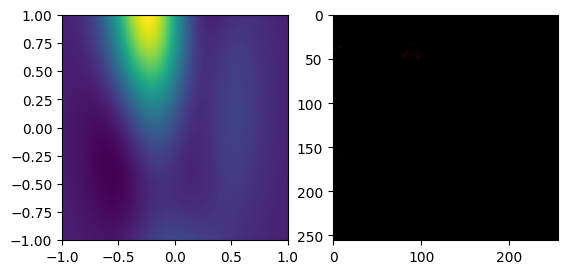

0.04534579999999977

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


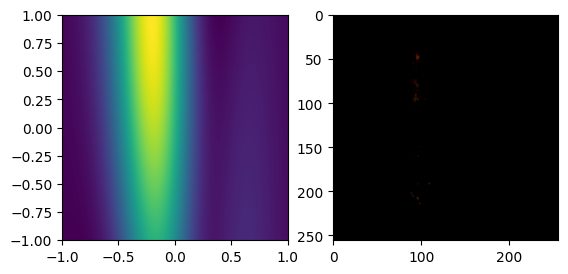

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.04979670000000169


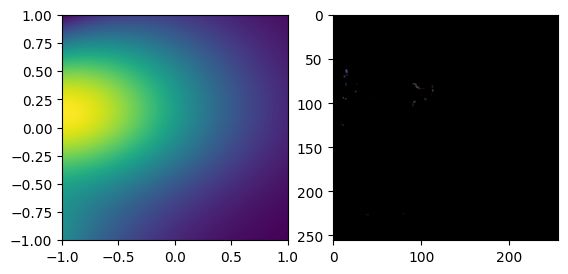

0.04304800000000242


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


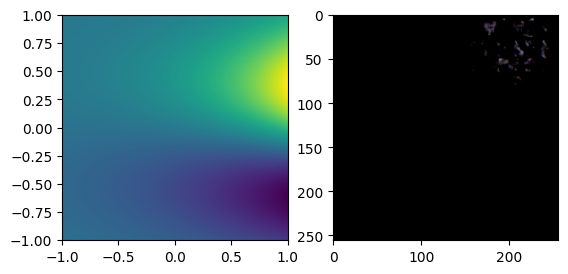

0.05345009999999917


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


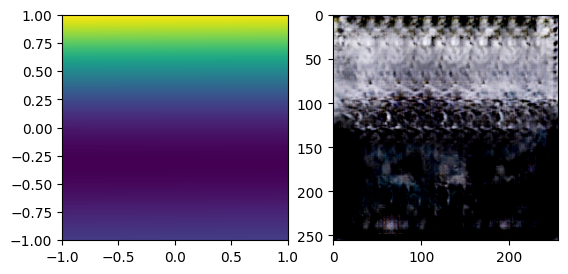

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.04330510000000132


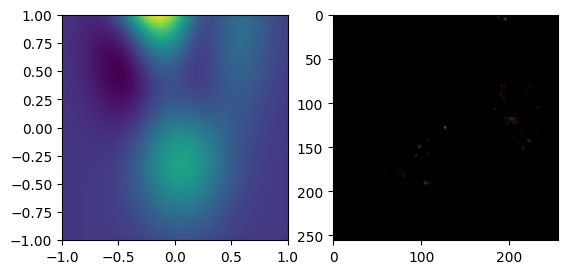

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.055358000000001795


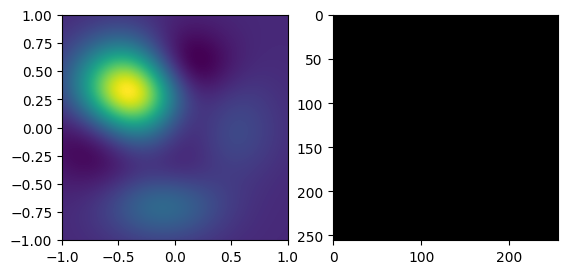

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.04113350000000082


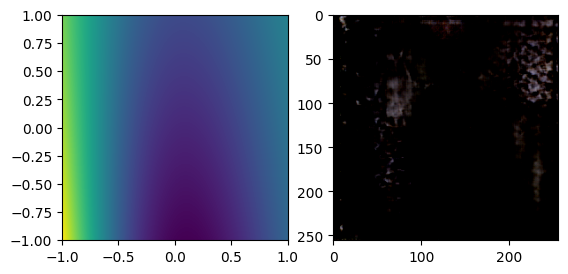

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.05738580000000226


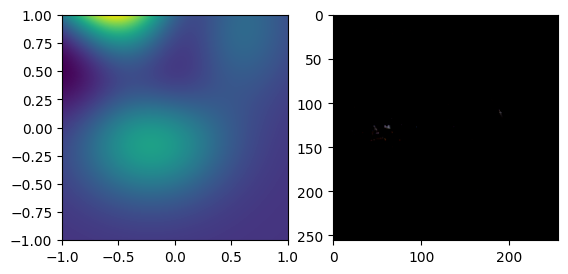

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.054225200000001195


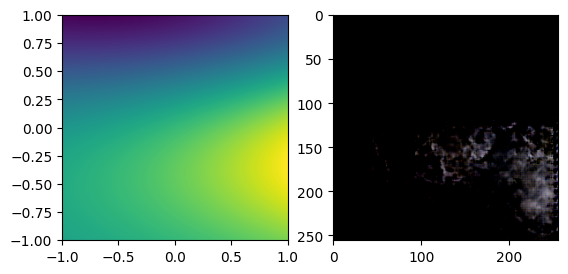

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.06007420000000252


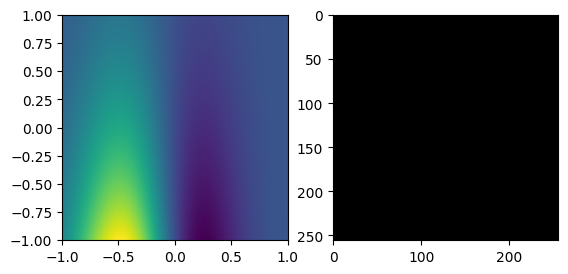

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.04754730000000151


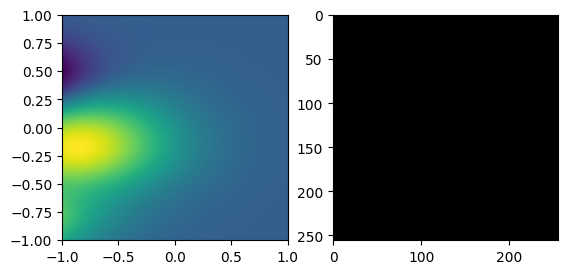

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.045810400000000584


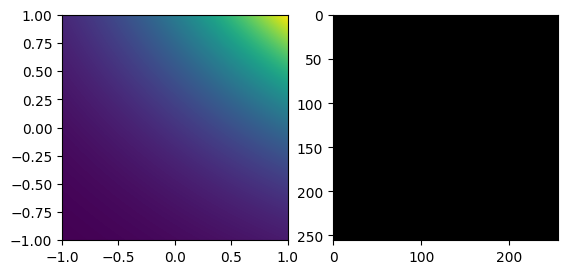

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


0.044263600000000736


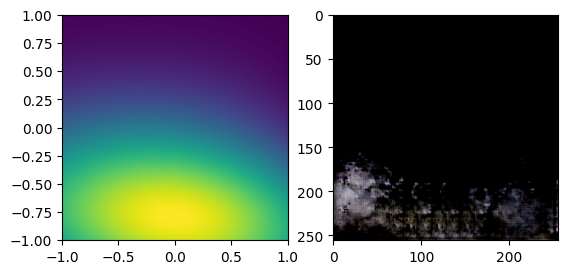

In [5]:
fac=np.linspace(0.95,0.05,20)
check = np.array([-1,1])
for ifac in fac:
    
    t = time.perf_counter()
    #ifac = np.random.choice(fac)
    #print(check*ifac-(1-ifac))
    x_draw = np.sort(np.random.uniform(-3,3,2))
    y_draw = np.sort(np.random.uniform(-3,3,2))
    X = np.linspace(x_draw[0],x_draw[1], 256)
    Y = np.linspace(y_draw[0],y_draw[1], 256)
    #X = np.linspace(-3*ifac, 3*ifac, 256)
    #Y = np.linspace(-3*ifac, 3*ifac, 256) 
    XX, YY = np.meshgrid(X,Y)
    
    ZZ = 2 * (1-XX)**2 * np.exp(-XX**2-(YY+1)**2)-1*(XX/5-XX**3-YY**5)*np.exp(-XX**2-YY**2)-1/3*np.exp(-(XX+1)**2-YY**2)
    dz = np.max(ZZ) - np.min(ZZ)
    ZZ= (ZZ.reshape((256,256,1)) - np.min(ZZ)) / dz 
    Z = ZZ * ifac - (1-ifac)
    
    #ZZ = np.sin(XX**2+YY**2).reshape((256,256,1))*2-1
    
    fig, ax = plt.subplots(1,2)
    ax[0].imshow(ZZ, extent=[-1, 1,-1,1])
    #ax[0].set_title(str(check*ifac-(1-ifac)))
    img = tf.cast(tf.constant(np.repeat(ZZ,3,axis=2)), tf.float32)
    prediction = model.generator(img[tf.newaxis, ...], training=True)

    print(time.perf_counter() - t)
    
    ax[1].imshow(prediction[0])
    plt.show()